In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [2]:
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
print(torch.__version__)

2.6.0+cpu


In [4]:
pip install torch-geometric

Note: you may need to restart the kernel to use updated packages.


In [5]:
import torch_geometric
from torch_geometric.utils import from_networkx, add_self_loops, degree
from torch_geometric.nn import MessagePassing
import torch_geometric.transforms as T
from torch_geometric.data import DataLoader
from torch_geometric.loader import NeighborSampler
import torch.nn as nn
import torch as th
import torch.nn.functional as F
# import dgl.function as fn
import networkx as nx
import pandas as pd
import socket
import struct
import random
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import pandas as pd

chunk_size = 500000  # Adjust based on memory availability
filtered_chunks = []  # List to store filtered data

# Read CSV in chunks
for chunk in pd.read_csv(r'', chunksize=chunk_size, low_memory=False): #upload dataset_final file path
    # Keep only 'Benign' and 'DDoS' attack types
    filtered_chunk = chunk[chunk['Attack'].str.startswith(('DDoS', 'DDOS')) | (chunk['Attack'] == 'Benign')]
    filtered_chunks.append(filtered_chunk)

# Combine all chunks into one DataFrame
data = pd.concat(filtered_chunks, ignore_index=True)

# Display the dataset size and attack counts
print("Filtered Data Shape:", data.shape)
print(data['Attack'].value_counts())

Filtered Data Shape: (18025837, 45)
Attack
Benign                    16635567
DDOS attack-HOIC           1080858
DDoS attacks-LOIC-HTTP      307300
DDOS attack-LOIC-UDP          2112
Name: count, dtype: int64


In [7]:
# Downsample to match DDQN sample length
benign_sample = data[data['Attack'] == 'Benign'].sample(n=937024, random_state=42)
ddos_data = data[data['Attack'].str.startswith(('DDoS', 'DDOS'))].sample(n=937024, random_state=42)
data = pd.concat([benign_sample, ddos_data])
data = data.sample(frac=1, random_state=42).reset_index(drop=True)
print(data['Attack'].value_counts())
print("Total samples after downsampling:", len(data))
print(data['Attack'].value_counts())

Attack
Benign                    937024
DDOS attack-HOIC          728816
DDoS attacks-LOIC-HTTP    206787
DDOS attack-LOIC-UDP        1421
Name: count, dtype: int64
Total samples after downsampling: 1874048
Attack
Benign                    937024
DDOS attack-HOIC          728816
DDoS attacks-LOIC-HTTP    206787
DDOS attack-LOIC-UDP        1421
Name: count, dtype: int64


In [8]:
def reduce_mem_usage(props):
    start_mem_usg = props.memory_usage().sum() / 1024**2 
    print("Memory usage of properties dataframe is :",start_mem_usg," MB")
    NAlist = [] 
    for col in props.columns:
        if props[col].dtype != object:  

            IsInt = False
            mx = props[col].max()
            mn = props[col].min()
            
            if not np.isfinite(props[col]).all(): 
                NAlist.append(col)
                props[col].fillna(mn-1,inplace=True)  
                   
            asint = props[col].fillna(0).astype(np.int64)
            result = (props[col] - asint)
            result = result.sum()
            if result > -0.01 and result < 0.01:
                IsInt = True

            if IsInt:
                if mn >= 0:
                    if mx < 255:
                        props[col] = props[col].astype(np.uint8)
                    elif mx < 65535:
                        props[col] = props[col].astype(np.uint16)
                    elif mx < 4294967295:
                        props[col] = props[col].astype(np.uint32)
                    else:
                        props[col] = props[col].astype(np.uint64)
                else:
                    if mn > np.iinfo(np.int8).min and mx < np.iinfo(np.int8).max:
                        props[col] = props[col].astype(np.int8)
                    elif mn > np.iinfo(np.int16).min and mx < np.iinfo(np.int16).max:
                        props[col] = props[col].astype(np.int16)
                    elif mn > np.iinfo(np.int32).min and mx < np.iinfo(np.int32).max:
                        props[col] = props[col].astype(np.int32)
                    elif mn > np.iinfo(np.int64).min and mx < np.iinfo(np.int64).max:
                        props[col] = props[col].astype(np.int64)    
            
            else:
                props[col] = props[col].astype(np.float32)
    print("___MEMORY USAGE AFTER COMPLETION:___")
    mem_usg = props.memory_usage().sum() / 1024**2 
    print("Memory usage is: ",mem_usg," MB")
    print("This is ",100*mem_usg/start_mem_usg,"% of the initial size")
    return props, NAlist

In [9]:
data, _ = reduce_mem_usage(data)

Memory usage of properties dataframe is : 643.4034461975098  MB


c:\Users\Anusnekhaa Narendran\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\dtypes\astype.py:134: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=True)


___MEMORY USAGE AFTER COMPLETION:___
Memory usage is:  250.21252822875977  MB
This is  38.88890084557464 % of the initial size


In [10]:
mapping = { 
    'DDOS attack-HOIC': 'DDoS attack',
    'DDOS attack-LOIC-UDP': 'DDoS attack',
    'DDoS attacks-LOIC-HTTP': 'DDoS attack',
    'Benign': 'Benign',
}

def transform_multi_label(data):
    print("Before Transformation:\n", data['Attack'].value_counts())
    data['Attack'] = data['Attack'].map(mapping).fillna(data['Attack'])  # Keep other attacks unchanged
    print("\nAfter Transformation:\n", data['Attack'].value_counts())
    return data


In [11]:
data = transform_multi_label(data)

Before Transformation:
 Attack
Benign                    937024
DDOS attack-HOIC          728816
DDoS attacks-LOIC-HTTP    206787
DDOS attack-LOIC-UDP        1421
Name: count, dtype: int64

After Transformation:
 Attack
DDoS attack    937024
Benign         937024
Name: count, dtype: int64


In [12]:
data.drop(columns=['PROTOCOL', 'L7_PROTO', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', \
                   'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE'],inplace=True)


In [13]:
print(data.Label.value_counts())

Label
1    937024
0    937024
Name: count, dtype: int64


In [14]:
data['IPV4_SRC_ADDR'] = data.IPV4_SRC_ADDR.apply(str)
data['L4_SRC_PORT'] = data.L4_SRC_PORT.apply(int)
data['L4_SRC_PORT'] = data.L4_SRC_PORT.apply(str)
data['IPV4_DST_ADDR'] = data.IPV4_DST_ADDR.apply(str)
data['L4_DST_PORT'] = data.L4_DST_PORT.apply(int)
data['L4_DST_PORT'] = data.L4_DST_PORT.apply(str)
data['IPV4_SRC_ADDR'] = data['IPV4_SRC_ADDR'] + ':' + data['L4_SRC_PORT']
data['IPV4_DST_ADDR'] = data['IPV4_DST_ADDR'] + ':' + data['L4_DST_PORT']
data.rename(columns={"IPV4_SRC_ADDR": "saddr"},inplace = True)
data.rename(columns={"IPV4_DST_ADDR": "daddr"},inplace = True)
data.drop(columns=['L4_SRC_PORT', 'L4_DST_PORT'],inplace=True)

In [15]:
print(data.head)

<bound method NDFrame.head of                         saddr              daddr  IN_BYTES  IN_PKTS  \
0            18.219.9.1:57333    172.31.69.25:80       232        5   
1          172.31.69.16:54019  216.58.198.74:443      2141       20   
2          18.216.24.42:56341    172.31.69.28:80       527        5   
3          18.219.32.43:54150    172.31.69.25:80       232        5   
4          172.31.66.22:62399      172.31.0.2:53       132        2   
...                       ...                ...       ...      ...   
1874043   172.31.64.112:56709      172.31.0.2:53       105        1   
1874044  18.216.200.189:58881    172.31.69.25:80       232        5   
1874045    172.31.67.80:49824      172.31.0.2:53        65        1   
1874046    164.52.6.146:58681  172.31.65.20:1723        44        1   
1874047    172.31.66.74:51948      172.31.0.2:53        64        1   

         OUT_BYTES  OUT_PKTS  FLOW_DURATION_MILLISECONDS  DURATION_IN  \
0             1136         4                

In [16]:
label_ground_truth = data[["saddr", "daddr", "Label"]]
class_ground_truth = data[["saddr", "daddr", "Attack"]]
# data = pd.get_dummies(data, columns = ['flgs_number','state_number', 'proto_number']) # One Hot Encoding for categorical data

In [17]:
data = data.reset_index()
data.replace([np.inf, -np.inf], np.nan,inplace = True)
data.fillna(0,inplace = True)
data.drop(columns=['index'],inplace=True)
print(data.head)

<bound method NDFrame.head of                         saddr              daddr  IN_BYTES  IN_PKTS  \
0            18.219.9.1:57333    172.31.69.25:80       232        5   
1          172.31.69.16:54019  216.58.198.74:443      2141       20   
2          18.216.24.42:56341    172.31.69.28:80       527        5   
3          18.219.32.43:54150    172.31.69.25:80       232        5   
4          172.31.66.22:62399      172.31.0.2:53       132        2   
...                       ...                ...       ...      ...   
1874043   172.31.64.112:56709      172.31.0.2:53       105        1   
1874044  18.216.200.189:58881    172.31.69.25:80       232        5   
1874045    172.31.67.80:49824      172.31.0.2:53        65        1   
1874046    164.52.6.146:58681  172.31.65.20:1723        44        1   
1874047    172.31.66.74:51948      172.31.0.2:53        64        1   

         OUT_BYTES  OUT_PKTS  FLOW_DURATION_MILLISECONDS  DURATION_IN  \
0             1136         4                

In [18]:
scaler = StandardScaler()
cols_to_norm = list(set(list(data.iloc[:, 2:].columns ))  - set(list(['Label']))  - set(list(['Attack'])) )
print(data[cols_to_norm].describe()) # Check if there's any too large value
print(cols_to_norm)

c:\Users\Anusnekhaa Narendran\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1010: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


       DST_TO_SRC_SECOND_BYTES       MAX_TTL  NUM_PKTS_1024_TO_1514_BYTES  \
count             1.874048e+06  1.874048e+06                 1.874048e+06   
mean              6.772157e+16  9.661645e+01                 2.135051e+00   
std                        inf  5.101531e+01                 2.161750e+02   
min               0.000000e+00  0.000000e+00                 0.000000e+00   
25%               1.920000e+02  1.000000e+02                 0.000000e+00   
50%               1.147000e+03  1.270000e+02                 0.000000e+00   
75%               1.147000e+03  1.270000e+02                 0.000000e+00   
max               1.269102e+23  2.550000e+02                 1.058760e+05   

       DST_TO_SRC_AVG_THROUGHPUT  TCP_WIN_MAX_IN  NUM_PKTS_128_TO_256_BYTES  \
count               1.874048e+06    1.874048e+06               1.874048e+06   
mean                8.815355e+06    3.009425e+04               7.168221e-01   
std                 7.148426e+07    2.997555e+04               4.5139

In [19]:
data[cols_to_norm] = data[cols_to_norm].clip(lower=-1e9, upper=1e9)
data[cols_to_norm] = scaler.fit_transform(data[cols_to_norm])

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
     data, label_ground_truth, test_size=0.2, random_state=42, stratify=label_ground_truth.Label)
print(len(X_train))
print(len(X_test))

1499238
374810


In [ ]:
import pandas as pd

X_test.to_csv(r"", index=False) #upload test_gnn.csv path

In [23]:
print(X_train['Attack'].value_counts())
print(X_test['Attack'].value_counts())

Attack
DDoS attack    749619
Benign         749619
Name: count, dtype: int64
Attack
DDoS attack    187405
Benign         187405
Name: count, dtype: int64


In [24]:
print(X_test.Label.value_counts())

Label
1    187405
0    187405
Name: count, dtype: int64


In [25]:
# Assuming your original dataset contains Attack column:
label_mapping_train = data.loc[X_train.index][['Label', 'Attack']].drop_duplicates()
label_mapping_test = data.loc[X_test.index][['Label', 'Attack']].drop_duplicates()

print("Train Labels Mapping:\n", label_mapping_train)
print("Test Labels Mapping:\n", label_mapping_test)


Train Labels Mapping:
         Label       Attack
868475      1  DDoS attack
616974      0       Benign
Test Labels Mapping:
          Label       Attack
1151538      1  DDoS attack
532633       0       Benign


In [26]:
X_train['h'] = X_train[ cols_to_norm ].values.tolist()

In [27]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
attack_labels = le.fit_transform(X_train['Attack'])
class_map = le.classes_
print(class_map)
print("Attack label mapping:", dict(zip(class_map, range(len(class_map)))))

['Benign' 'DDoS attack']
Attack label mapping: {'Benign': 0, 'DDoS attack': 1}


In [28]:
# Convert NetworkX graph to PyG graph
G_nx = nx.from_pandas_edgelist(X_train, "saddr", "daddr", ['h', 'Label'], create_using=nx.MultiDiGraph())
G_pyg = from_networkx(G_nx)

num_nodes = G_pyg.num_nodes
num_edges = G_pyg.num_edges

G_pyg.x = th.ones(num_nodes, len(X_train['h'].iloc[0])) 

edge_attr_list = []
edge_label_list = []

for u, v, key, data in G_nx.edges(keys=True, data=True):
    edge_attr_list.append(data['h']) 
    edge_label_list.append(data['Label']) 

G_pyg.edge_attr = th.tensor(edge_attr_list, dtype=th.float32)
G_pyg.edge_label = th.tensor(edge_label_list, dtype=th.long)
G_pyg.edge_class = th.tensor(attack_labels, dtype=th.long)

print("Number of edges in G_pyg:", G_pyg.num_edges)
print("Number of node in G_pyg:", G_pyg.num_nodes)
print("Shape of node in G_pyg:", G_pyg.x.shape)
print("Shape of edge attr in G_pyg:", G_pyg.edge_attr.shape)
print("Shape of edge label in G_pyg:", G_pyg.edge_label.shape)
print("Shape of edge class in G_pyg:", G_pyg.edge_class.shape)

Number of edges in G_pyg: 1499238
Number of node in G_pyg: 904433
Shape of node in G_pyg: torch.Size([904433, 28])
Shape of edge attr in G_pyg: torch.Size([1499238, 28])
Shape of edge label in G_pyg: torch.Size([1499238])
Shape of edge class in G_pyg: torch.Size([1499238])


In [29]:
print("Unique edge labels:", th.unique(G_pyg.edge_label))  # Should print tensor([0, 1])


Unique edge labels: tensor([0, 1])


In [30]:
class EGraphSAGEConv(MessagePassing):
    def __init__(self, node_in_channels, edge_in_channels, out_channels):
        super(EGraphSAGEConv, self).__init__(aggr='mean')  # mean aggregation
        self.lin_node = nn.Linear(node_in_channels, out_channels)
        self.lin_edge = nn.Linear(edge_in_channels, out_channels)
        self.lin_update = nn.Linear(node_in_channels + out_channels, out_channels) # out_channels * 2

    def forward(self, x, edge_index, edge_attr):
        # x: Node features, edge_attr: Edge features, edge_index: Connectivity
        edge_index, _ = add_self_loops(edge_index, num_nodes=x.size(0))

        if edge_attr is not None:
            if edge_attr.size(0) != edge_index.size(1):
                loop_attr = th.zeros((edge_index.size(1) - edge_attr.size(0), edge_attr.size(1))).to(edge_attr.device)
                edge_attr = th.cat([edge_attr, loop_attr], dim=0)
        else:
            print("edge_attr is unexist")
        
        # Propagate and aggregate neighbor information
        return self.propagate(edge_index, x=x, edge_attr=edge_attr)

    def message(self, x_j, edge_attr):
        # x_j represents the adjacent nodes of x
        # Compute messages by combining node and edge features
        return self.lin_node(x_j) + self.lin_edge(edge_attr)

    def update(self, aggr_out, x):
        # Update node features after message passing
        return self.lin_update(th.cat([x, aggr_out], dim=1))
    
class MLPPredictor(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(MLPPredictor, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_channels * 2, in_channels),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(in_channels, out_channels)
        )

    def forward(self, data, z):
        row, col = data.edge_index
        edge_feat = th.cat([z[row], z[col]], dim=1)
        return self.fc(edge_feat)


class EGraphSAGE(nn.Module):
    def __init__(self, node_in_channels, edge_in_channels, hidden_channels, out_channels):
        super(EGraphSAGE, self).__init__()
        self.conv1 = EGraphSAGEConv(node_in_channels, edge_in_channels, hidden_channels)
        self.conv2 = EGraphSAGEConv(hidden_channels, edge_in_channels, hidden_channels)
        self.mlp_predictor = MLPPredictor(hidden_channels, out_channels)

    def forward(self, data):
        x, edge_index, edge_attr = data.x, data.edge_index, data.edge_attr
        x = F.relu(self.conv1(x, edge_index, edge_attr))
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index, edge_attr)
        return self.mlp_predictor(data, x)

In [31]:
device = th.device("cuda:0" if th.cuda.is_available() else "cpu")
print(device)

cpu


In [32]:
th.cuda.empty_cache()

In [33]:
labels = G_pyg.edge_label.cpu().numpy()
class_weights = class_weight.compute_class_weight('balanced',
                                                  classes=np.unique(labels),
                                                  y=labels)
print(class_weights)

[1. 1.]


In [34]:
model = EGraphSAGE(node_in_channels=G_pyg.num_node_features, 
                         edge_in_channels=G_pyg.num_edge_features,
                         hidden_channels=32,  # Reduced hidden channels to simplify
                         out_channels=2).to(device)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        nn.init.constant_(m.bias, 0)

model.apply(init_weights)

# Loss and optimizer
labels = G_pyg.edge_label.cpu().numpy()
class_weights = class_weight.compute_class_weight('balanced',
                                                  classes=np.unique(labels),
                                                  y=labels)
class_weights = th.FloatTensor(class_weights).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = th.optim.Adam(model.parameters(), lr=0.0001, weight_decay=4e-5) 

Epoch: 0
Epoch 0, Loss: 0.0002, Accuracy: 0.9714
Epoch: 1
Epoch 1, Loss: 0.0000, Accuracy: 0.9992
Epoch: 2
Epoch 2, Loss: 0.0000, Accuracy: 0.9997
Epoch: 3
Epoch 3, Loss: 0.0000, Accuracy: 0.9998
Epoch: 4
Epoch 4, Loss: 0.0000, Accuracy: 0.9999
Epoch: 5
Epoch 5, Loss: 0.0000, Accuracy: 0.9999
Epoch: 6
Epoch 6, Loss: 0.0000, Accuracy: 0.9999
Epoch: 7
Epoch 7, Loss: 0.0000, Accuracy: 0.9999
Epoch: 8
Epoch 8, Loss: 0.0000, Accuracy: 0.9999
Epoch: 9
Epoch 9, Loss: 0.0000, Accuracy: 0.9999
Training is over


C:\Users\Anusnekhaa Narendran\AppData\Local\Temp\ipykernel_15104\2443750753.py:126: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


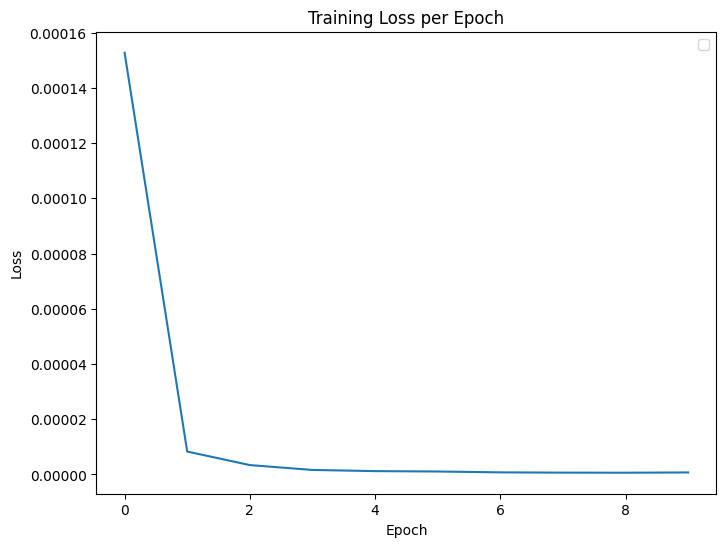

C:\Users\Anusnekhaa Narendran\AppData\Local\Temp\ipykernel_15104\2443750753.py:135: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


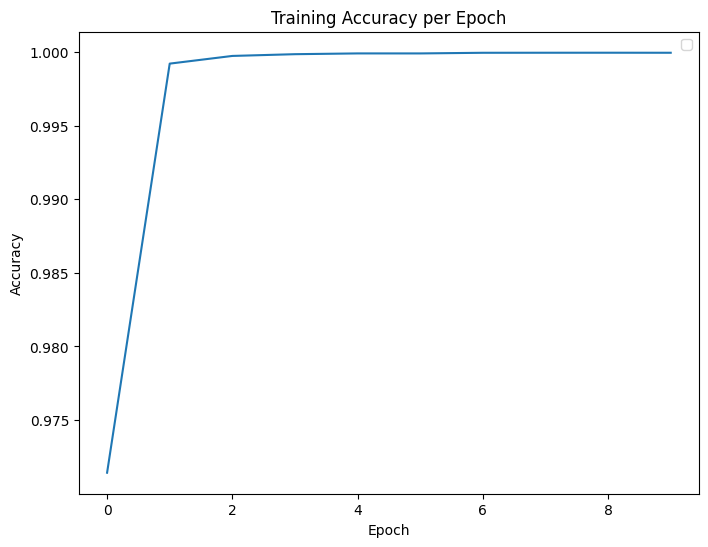

In [35]:
from torch_geometric.utils import subgraph
from torch_geometric.data import Data

def compute_accuracy(pred, labels):
    return (pred.argmax(1) == labels).float().mean().item()

G_pyg.edge_label = G_pyg.edge_label.to(device)
G_pyg.edge_attr = G_pyg.edge_attr.to(device)

def generate_edge_based_batches_with_node_expansion(graph, batch_size, min_nodes):
    num_edges = graph.edge_index.size(1)  # Get total number of edges
    edge_indices = th.arange(num_edges)   # Create list of edge indices
    num_edges_processed = 0
    
    while num_edges_processed < num_edges:
        # Select a batch of edges
        batch_edge_indices = edge_indices[num_edges_processed : min(num_edges_processed + batch_size, num_edges)]
        edge_index = graph.edge_index[:, batch_edge_indices]
        
        # Update the number of edges processed
        num_edges_processed += batch_size
        
        # Get the unique nodes associated with these edges
        batch_nodes = th.cat([edge_index[0], edge_index[1]]).unique()

        # Check if the batch has enough unique nodes
        while batch_nodes.size(0) < min_nodes:
            # Sample additional neighboring nodes to ensure diversity
            additional_edges = int(batch_size / 8)  # Ensure additional_edges is an integer
            batch_edge_indices = th.cat([batch_edge_indices, edge_indices[num_edges_processed : min(num_edges_processed + additional_edges, num_edges)]])
            edge_index = graph.edge_index[:, batch_edge_indices]
            batch_nodes = th.cat([edge_index[0], edge_index[1]]).unique()
            num_edges_processed += additional_edges

            # Avoid potential infinite loops by breaking if no more edges can be added
            if num_edges_processed >= num_edges:
                break

        # Create subgraph from the selected nodes and edges
        edge_index, _, edge_mask = subgraph(batch_nodes, graph.edge_index, relabel_nodes=True, return_edge_mask=True)

        # Use edge_mask to select edge attributes and labels
        edge_attr = graph.edge_attr[edge_mask]
        edge_label = graph.edge_label[edge_mask]

        yield batch_nodes, edge_index, edge_attr, edge_label

batch_size = 512
num_epochs = 10

epoch_losses = []
epoch_accuracies = []

for epoch in range(num_epochs):
    print(f'Epoch: {epoch}')
    
    all_preds = []
    all_labels = []
    total_loss = 0
    
    try:
        for batch_idx, (batch_nodes, edge_index, edge_attr, edge_label) in enumerate(generate_edge_based_batches_with_node_expansion(G_pyg, batch_size, 20)):
            batch = Data(x=G_pyg.x[batch_nodes], edge_index=edge_index, edge_attr=edge_attr, edge_label=edge_label)
            
            if batch.edge_index.size(1) == 0 or batch.edge_label.size(0) == 0:
                print(f"Warning: Empty batch at batch {batch_idx}")
                continue
                
            if batch is None or batch.num_nodes == 0:
                print(f"Warning: Empty batch at Batch {batch_idx}")
                continue 
    
            if th.isnan(batch.x).any() or th.isinf(batch.x).any() or th.isnan(batch.edge_attr).any() or th.isinf(batch.edge_attr).any():
                print(f"Warning: batch x and edge_attr contains NaN or Inf at Batch {batch_idx}")
                continue 
                
            try:
                batch = batch.to(device)
            except Exception as batch_error:
                print(f"Error moving batch to device at Batch {batch_idx}: {batch_error}")
                continue
            
            try:
                out = model(batch)
    
                if th.isnan(out).any() or th.isinf(out).any():
                    print(f"Warning: out contains NaN or Inf at Batch {batch_idx}")
                    continue 
                
                loss = criterion(out, batch.edge_label)
                total_loss += loss.item()

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
                all_preds.append(out)
                all_labels.append(batch.edge_label)
                
            except Exception as forward_error:
                print(f"Error during forward/backward pass at Epoch {epoch}, Batch {batch_idx}: {forward_error}")
                continue
        
        all_preds = th.cat(all_preds)
        all_labels = th.cat(all_labels)
        
        epoch_accuracy = compute_accuracy(all_preds, all_labels)
        epoch_loss = total_loss / len(all_preds)  # Average loss per epoch

        epoch_losses.append(epoch_loss)
        epoch_accuracies.append(epoch_accuracy)
        
        print(f'Epoch {epoch}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.4f}')
        
    except Exception as e:
        print(f"An error occurred at epoch {epoch}, batch {batch_idx}: {str(e)}")

print("Training is over")

# Plot Training Loss
plt.figure(figsize=(8, 6))
plt.plot(range(num_epochs), epoch_losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss per Epoch')
plt.legend()
plt.show()

# Plot Training Accuracy
plt.figure(figsize=(8, 6))
plt.plot(range(num_epochs), epoch_accuracies)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training Accuracy per Epoch')
plt.legend()
plt.show()


In [ ]:
import os
import json

# Save model weights in .h5 format
th.save(model.state_dict(), r"") #save gnn model weights.pth file in a path

print("Model weights and architecture saved successfully.")


Model weights and architecture saved successfully.


In [37]:
from sklearn.preprocessing import LabelEncoder

test_le = LabelEncoder()
X_test['Attack'] = test_le.fit_transform(X_test['Attack'])
test_class_map = test_le.classes_
print(test_class_map)
print("Attack label mapping:", dict(zip(test_class_map, range(len(test_class_map)))))

['Benign' 'DDoS attack']
Attack label mapping: {'Benign': 0, 'DDoS attack': 1}


In [38]:
X_test['h'] = X_test[ cols_to_norm ].values.tolist()

G_nx_test = nx.from_pandas_edgelist(X_test, "saddr", "daddr", ['h', 'Label', 'Attack'], create_using=nx.MultiDiGraph())

G_pyg_test = from_networkx(G_nx_test)

test_num_nodes = G_pyg_test.num_nodes
test_num_edges = G_pyg_test.num_edges

G_pyg_test.x = th.ones(test_num_nodes, len(X_test['h'].iloc[0]))

test_edge_attr_list = []
test_edge_label_list = []
test_edge_class_list = []

for u, v, key, data in G_nx_test.edges(keys=True, data=True):
    test_edge_attr_list.append(data['h']) 
    test_edge_label_list.append(data['Label']) 
    test_edge_class_list.append(data['Attack'])

G_pyg_test.edge_attr = th.tensor(test_edge_attr_list, dtype=th.float32)
benign_class_index = test_le.transform(['Benign'])[0]
edge_labels_binary = [0 if attack == benign_class_index else 1 for attack in test_edge_class_list]
G_pyg_test.edge_label = th.tensor(edge_labels_binary, dtype=th.long)

G_pyg_test.edge_class = th.tensor(test_edge_class_list, dtype=th.long)

print("Number of edges in G_pyg_test:", G_pyg_test.num_edges)
print("Number of node in G_pyg_test:", G_pyg_test.num_nodes)
print("Shape of node in G_pyg_test:", G_pyg_test.x.shape)
print("Shape of edge attr in G_pyg_test:", G_pyg_test.edge_attr.shape)
print("Shape of edge label in G_pyg_test:", G_pyg_test.edge_label.shape)
print("Shape of edge class in G_pyg_test:", G_pyg_test.edge_class.shape)

Number of edges in G_pyg_test: 374810
Number of node in G_pyg_test: 310477
Shape of node in G_pyg_test: torch.Size([310477, 28])
Shape of edge attr in G_pyg_test: torch.Size([374810, 28])
Shape of edge label in G_pyg_test: torch.Size([374810])
Shape of edge class in G_pyg_test: torch.Size([374810])


In [ ]:
state_dict = th.load(r"") #upload gnn model weights path
print(state_dict.keys())

odict_keys(['conv1.lin_node.weight', 'conv1.lin_node.bias', 'conv1.lin_edge.weight', 'conv1.lin_edge.bias', 'conv1.lin_update.weight', 'conv1.lin_update.bias', 'conv2.lin_node.weight', 'conv2.lin_node.bias', 'conv2.lin_edge.weight', 'conv2.lin_edge.bias', 'conv2.lin_update.weight', 'conv2.lin_update.bias', 'mlp_predictor.fc.0.weight', 'mlp_predictor.fc.0.bias', 'mlp_predictor.fc.3.weight', 'mlp_predictor.fc.3.bias'])


In [40]:
import numpy as np
import pandas as pd
import os
import tensorflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import shuffle
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import optimizers
from tensorflow.keras import backend as K
import logging.config
from gym import  spaces
import gym
import json
import sys
import time

In [ ]:
class data_cls:
    def __init__(self, train_test, attack_map, **kwargs):
        self.train_test = train_test
        
        if self.train_test == 'train':
            self.train_path = r"" #upload train_gnn.csv path
        else:
            self.test_path = r"" #upload test_gnn.csv path

        self.attack_map =   attack_map 
        self.attack_types = list(attack_map.keys())
        
        self.loaded = False
        
    
    def get_batch(self, batch_size=100):
        
        if self.loaded is False:
            self._load_df()
            
        indexes = list(range(self.index,self.index+batch_size))    
        if max(indexes)>self.data_shape[0]-1:
            dif = max(indexes)-self.data_shape[0]
            indexes[len(indexes)-dif-1:len(indexes)] = list(range(dif+1))
            self.index=batch_size-dif
            batch = self.df.iloc[indexes]
        else: 
            batch = self.df.iloc[indexes]
            self.index += batch_size    
        
        map_type = pd.Series(index=self.attack_types,data=np.arange(len(self.attack_types))).to_dict()
        labels = batch[label_col].map(self.attack_map).map(map_type).values
        del(batch[label_col])
            
        return np.array(batch),labels
    
    def get_full(self):

        self._load_df()
        
        batch = self.df
        map_type = pd.Series(index=self.attack_types,data=np.arange(len(self.attack_types))).to_dict()
        labels = batch[label_col].map(self.attack_map).map(map_type).values
        
        del(batch[label_col])
        
        return np.array(batch), labels
    
    def get_shape(self):
        if self.loaded is False:
            self._load_df()
        
        self.data_shape = self.df.shape
        return self.data_shape
    
    def _load_df(self):
        if self.train_test == 'train':
            self.df = pd.read_csv(self.test_path, dtype={33: float})

        else:
            self.df = pd.read_csv(self.test_path)
            
        self.index=np.random.randint(0,self.df.shape[0]-1,dtype=np.int32)
        self.loaded = True

In [42]:
class NetworkClassificationEnv(gym.Env, data_cls):
    def __init__(self,train_test, attack_map, **kwargs):
        data_cls.__init__(self,train_test, attack_map,**kwargs)
        self.data_shape = self.get_shape()
        self.batch_size = kwargs.get('batch_size', 1) 
        self.fails_episode = kwargs.get('fails_episode', 10) 
        
        # Gym spaces
        self.action_space = spaces.Discrete(len(self.attack_types))
        self.observation_space = spaces.Discrete(self.data_shape[0])
        
        self.observation_len = self.data_shape[1]-1
        
        self.counter = 0

    def _update_state(self):
        self.states,self.labels = self.get_batch(self.batch_size)
        

    def reset(self):
        self.states,self.labels = self.get_batch(self.batch_size)
        self.counter = 0
        
        return self.states
    def _get_rewards(self,actions):
        self.reward = 0
        if actions == self.labels:
            self.reward = 1
        else: 
            self.counter += 1

    def step(self,actions):
        self._get_rewards(actions)
            
        self._update_state()

        if self.counter >= self.fails_episode:
            self.done = True
        else:
            self.done = False
            
        return self.states, self.reward, self.done

In [43]:
import tensorflow as tf
from tensorflow.keras import backend as K

@tf.keras.utils.register_keras_serializable(package="Custom", name="huber_loss")
def huber_loss(y_true, y_pred, clip_value=1.0):
    assert clip_value > 0.0, "clip_value must be positive."

    x = y_true - y_pred
    
    # Handle the case when clip_value is infinity
    if np.isinf(clip_value):
        return 0.5 * tf.square(x)

    # Define condition for the quadratic part
    condition = tf.abs(x) < clip_value

    # Compute squared and linear losses
    squared_loss = 0.5 * tf.square(x)
    linear_loss = clip_value * (tf.abs(x) - 0.5 * clip_value)

    # Use TensorFlow's conditional logic to return the appropriate loss
    return tf.where(condition, squared_loss, linear_loss)


In [ ]:
# Check if the weights and model files exist
weights_path = r"" #upload gnn weights .pth file
json_path = r"" #upload gnn_model.json path

if os.path.exists(weights_path) and os.path.exists(json_path):
    print("Model files exist.")
else:
    print("Model files are missing.")

Model files exist.


In [45]:
import json
import numpy as np
import pandas as pd
from tensorflow.keras.models import model_from_json
import matplotlib.pyplot as plt

import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import  confusion_matrix

In [46]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [ ]:
with open(json_path) as jfile:
    model = model_from_json(json.load(jfile))
model.load_weights(weights_path)
label_dict = r"" #upload label_dict.json file
with open(label_dict, "r") as f:
    label_dict = json.load(f)


model.compile(loss=huber_loss, optimizer="sgd")

env = NetworkClassificationEnv('test', label_dict)

In [48]:
total_reward = 0

label_col = 'Label'
    
true_labels = np.zeros(len(env.attack_types),dtype=int)
estimated_labels = np.zeros(len(env.attack_types),dtype=int)
estimated_correct_labels = np.zeros(len(env.attack_types),dtype=int)

states, labels = env.get_full()
q = model.predict(states)
actions = np.argmax(q, axis=1)        


labs, true_labels = np.unique(labels, return_counts=True)

for indx,a in enumerate(actions):
    estimated_labels[a] +=1              
    if a == labels[indx]:
        total_reward += 1
        estimated_correct_labels[a] += 1


Accuracy = estimated_correct_labels / true_labels
Mismatch = estimated_labels - true_labels
print('\r\nTotal reward: {} | Number of samples: {} | Accuracy = {}%'.format(total_reward,
      len(states),float(100*total_reward/len(states))))
outputs_df = pd.DataFrame(index = env.attack_types,columns = ["Estimated","Correct","Total","Acuracy"])
for indx,att in enumerate(env.attack_types):
    outputs_df.iloc[indx].Estimated = estimated_labels[indx]
    outputs_df.iloc[indx].Correct = estimated_correct_labels[indx]
    outputs_df.iloc[indx].Total = true_labels[indx]
    outputs_df.iloc[indx].Acuracy = Accuracy[indx]*100
    outputs_df.iloc[indx].Mismatch = abs(Mismatch[indx])

11713/11713 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step

Total reward: 358609 | Number of samples: 374810 | Accuracy = 95.67754328859955%


In [49]:
outputs_df

,Estimated,Correct,Total,Acuracy
Benign,183722,177505,187489,94.674888
DDoS attack,191088,181104,187321,96.681098


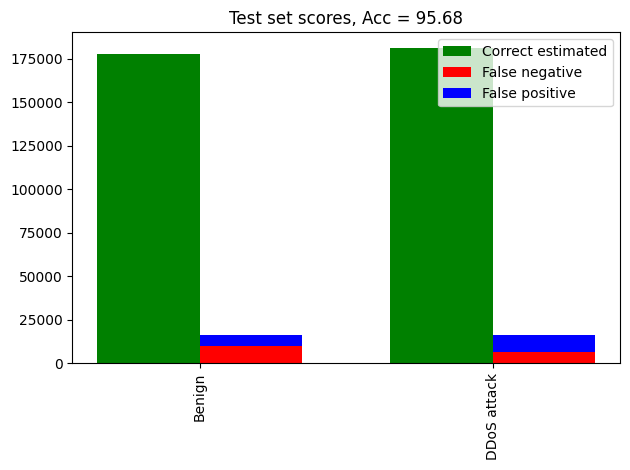

In [50]:
fig, ax = plt.subplots()
width = 0.35
pos = np.arange(len(true_labels))
p1 = plt.bar(pos, estimated_correct_labels,width,color='g')
p1 = plt.bar(pos+width,
             (np.abs(estimated_correct_labels-true_labels)),width,
             color='r')
p2 = plt.bar(pos+width,np.abs(estimated_labels-estimated_correct_labels),width,
             bottom=(np.abs(estimated_correct_labels-true_labels)),
             color='b')


ax.set_xticks(pos+width/2)
ax.set_xticklabels(env.attack_types,rotation='vertical')

ax.set_title('Test set scores, Acc = {:.2f}'.format(100*total_reward/len(states)))
plt.legend(('Correct estimated','False negative','False positive'))
plt.tight_layout()
plt.show()

Performance measures on Test data
Accuracy =  0.9568
F1 =  0.9568
Precision_score =  0.9570
recall_score =  0.9568
Normalized confusion matrix
[[0.95 0.05]
 [0.03 0.97]]


<Figure size 640x480 with 0 Axes>

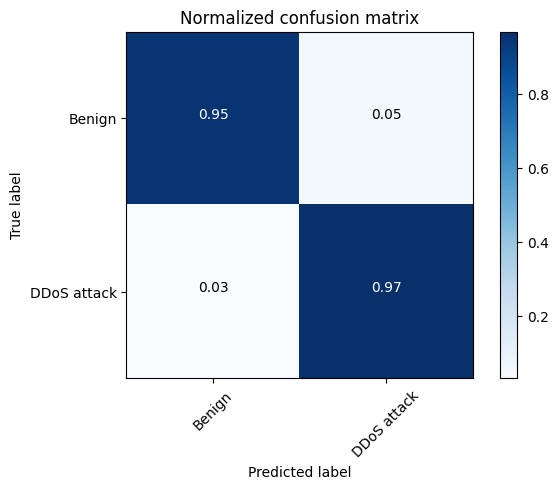

In [51]:
aggregated_data_test =labels

print('Performance measures on Test data')
print('Accuracy =  {:.4f}'.format(accuracy_score( aggregated_data_test,actions)))
print('F1 =  {:.4f}'.format(f1_score(aggregated_data_test,actions, average='weighted')))
print('Precision_score =  {:.4f}'.format(precision_score(aggregated_data_test,actions, average='weighted')))
print('recall_score =  {:.4f}'.format(recall_score(aggregated_data_test,actions, average='weighted')))

cnf_matrix = confusion_matrix(aggregated_data_test,actions)
np.set_printoptions(precision=2)
plt.figure()
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=env.attack_types, normalize=True,
                      title='Normalized confusion matrix')


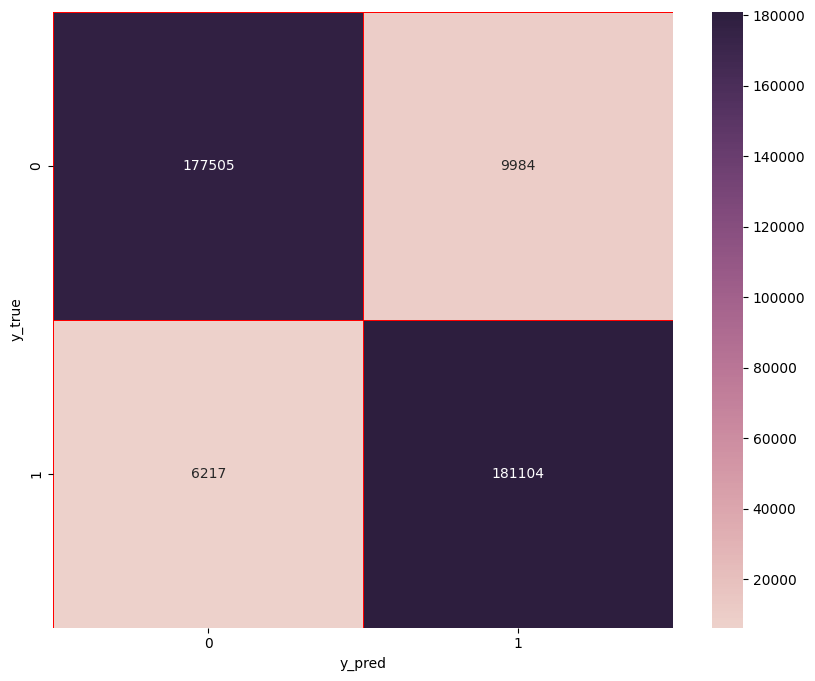

In [52]:
import seaborn as sns
cm=confusion_matrix(aggregated_data_test,actions)
f,ax=plt.subplots(figsize=(10,8))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax,cmap=sns.cubehelix_palette(as_cmap=True))
plt.xlabel("y_pred")
plt.ylabel("y_true")
plt.show()